In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train_norm = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test_norm = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print(f"Train shape: {x_train_norm.shape}")
print(f"Test shape: {x_test_norm.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Train shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


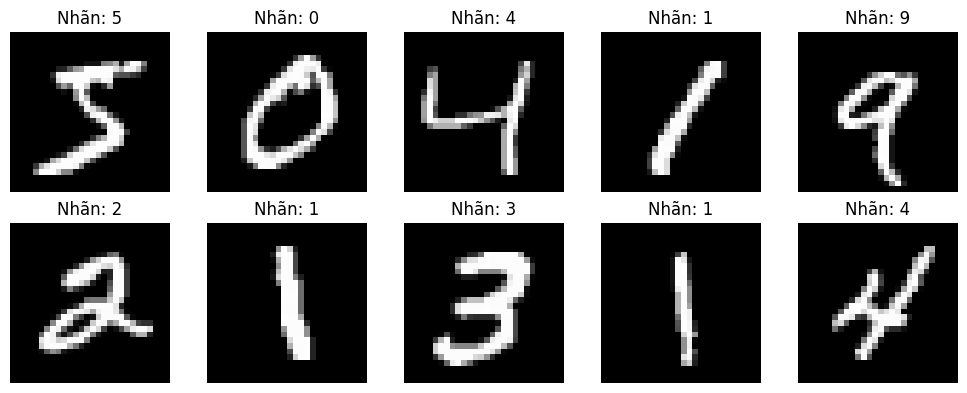

In [10]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Nhãn: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3), 
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\minh duc\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    x_train_norm, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(x_test_norm, y_test),
    callbacks=[early_stop]
)

Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9388 - loss: 0.1971 - val_accuracy: 0.9861 - val_loss: 0.0467
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9813 - loss: 0.0634 - val_accuracy: 0.9878 - val_loss: 0.0344
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9853 - loss: 0.0482 - val_accuracy: 0.9910 - val_loss: 0.0259
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9891 - loss: 0.0357 - val_accuracy: 0.9909 - val_loss: 0.0274
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9905 - loss: 0.0306 - val_accuracy: 0.9908 - val_loss: 0.0267
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9922 - loss: 0.0244 - val_accuracy: 0.9925 - val_loss: 0.0227
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9929 - loss: 0.0222 - val_accuracy: 0.9913 - val_loss: 0.0257
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9938 - loss: 0.0195 - val_accuracy: 0.

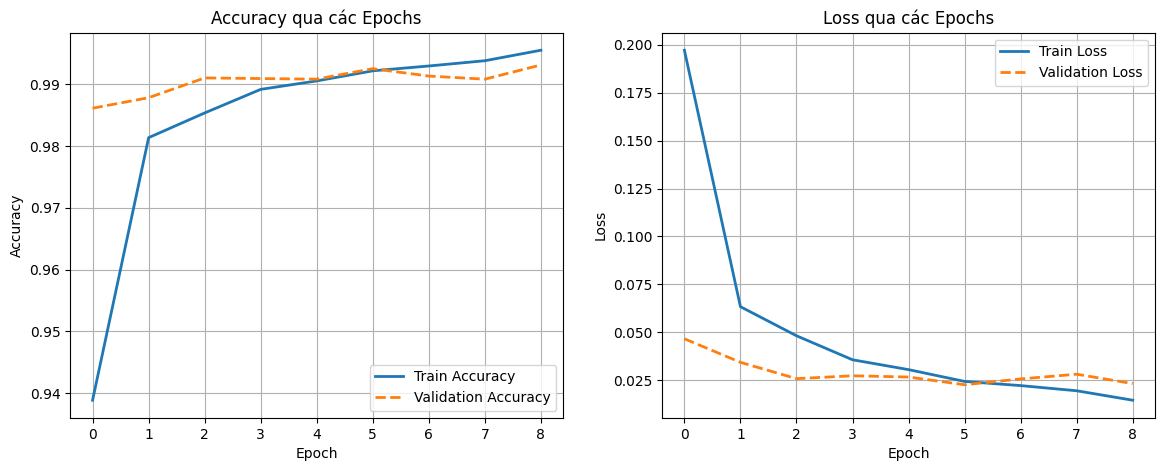

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linestyle='--', linewidth=2)
axes[0].set_title('Accuracy qua các Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Biểu đồ Loss
axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', linestyle='--', linewidth=2)
axes[1].set_title('Loss qua các Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.show()

In [7]:
os.makedirs("../models", exist_ok=True)
model.save("../models/digit_model.h5")
print("Đã lưu mô hình thành công tại models/digit_model.h5!")

Đã lưu mô hình thành công tại models/digit_model.h5!


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0     0.9959    0.9959    0.9959       980
           1     0.9930    0.9982    0.9956      1135
           2     0.9961    0.9922    0.9942      1032
           3     0.9931    0.9950    0.9941      1010
           4     0.9869    0.9959    0.9914       982
           5     0.9910    0.9899    0.9905       892
           6     0.9937    0.9906    0.9922       958
           7     0.9903    0.9903    0.9903      1028
           8     0.9918    0.9928    0.9923       974
           9     0.9930    0.9832    0.9880      1009

    accuracy                         0.9925     10000
   macro avg     0.9925    0.9924    0.9924     10000
weighted avg     0.9925    0.9925    0.9925     10000



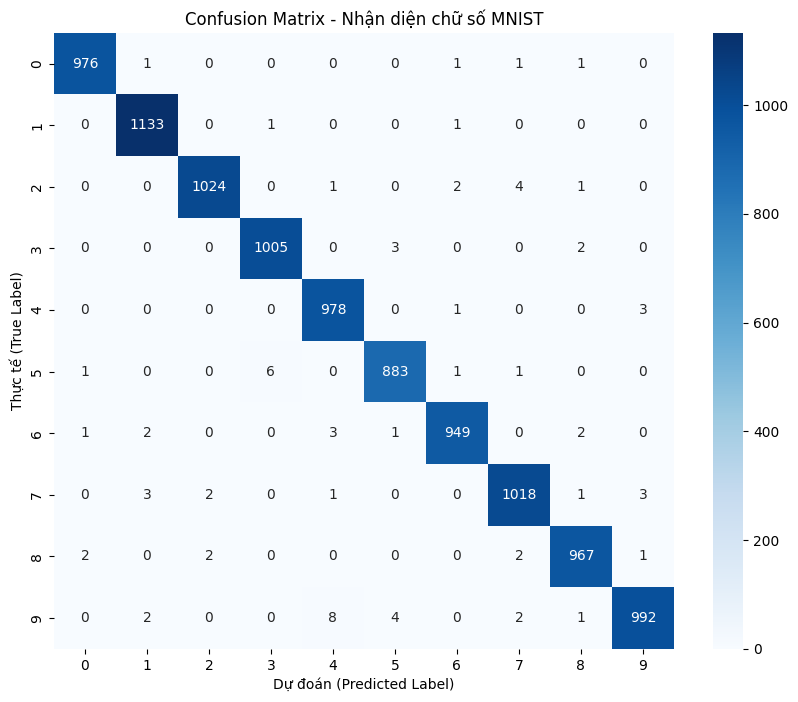

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
prob = model.predict(x_test_norm)
y_pred = np.argmax(prob, axis=1)

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix - Nhận diện chữ số MNIST')
plt.xlabel('Dự đoán (Predicted Label)')
plt.ylabel('Thực tế (True Label)')
plt.show()

Tổng số lượng mẫu chữ số '1' trong tập train: 6742
Danh sách 20 chỉ số đầu tiên: [  3   6   8  14  23  24  40  59  67  70  72  77  78  99 102 104 105 112
 113 124]


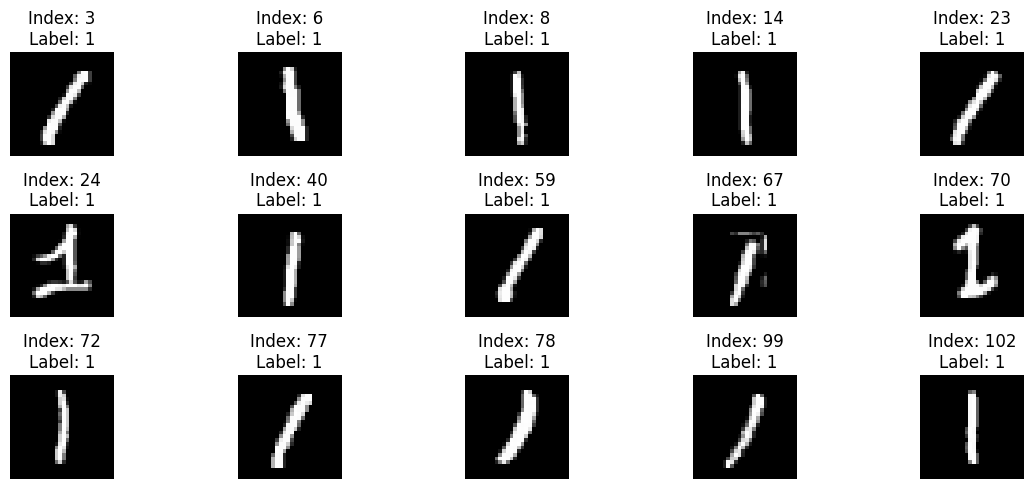

In [9]:

digit_1_indices = np.where(y_train == 1)[0]

print(f"Tổng số lượng mẫu chữ số '1' trong tập train: {len(digit_1_indices)}")
print(f"Danh sách 20 chỉ số đầu tiên: {digit_1_indices[:20]}")

plt.figure(figsize=(12, 5))
for i in range(15):
    idx = digit_1_indices[i]
    plt.subplot(3, 5, i + 1)
    img = x_train[idx].reshape(28, 28)
    plt.imshow(img, cmap='gray')
    plt.title(f"Index: {idx}\nLabel: {y_train[idx]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:

import cv2


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

def generate_custom_digit_1(count=3000):
   
    custom_images = []
    custom_labels = []
    
    for _ in range(count):
        img = np.zeros((28, 28), dtype=np.uint8)
   
        x_center = np.random.randint(12, 16)
        y_top = np.random.randint(4, 8)
        y_bottom = np.random.randint(20, 24)
        thickness = np.random.randint(2, 4)

        cv2.line(img, (x_center, y_top), (x_center, y_bottom), 255, thickness)

        if np.random.rand() > 0.2:
            hook_len = np.random.randint(3, 6)
            cv2.line(img, (x_center, y_top), (x_center - hook_len, y_top + hook_len), 255, thickness)
            
        if np.random.rand() > 0.2:
            base_len = np.random.randint(4, 8)
            cv2.line(img, (x_center - base_len, y_bottom), (x_center + base_len, y_bottom), 255, thickness)
           
        img = cv2.GaussianBlur(img, (3, 3), 0)
        
        custom_images.append(img)
        custom_labels.append(1)
        
    return np.array(custom_images), np.array(custom_labels)

custom_x1, custom_y1 = generate_custom_digit_1(count=4000)

x_train_augmented = np.concatenate([x_train, custom_x1], axis=0)
y_train_augmented = np.concatenate([y_train, custom_y1], axis=0)

x_train_norm = x_train_augmented.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test_norm = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0
y_train_norm = y_train_augmented

print(f"Tổng số mẫu train sau khi bổ sung số 1 kiểu mới: {len(x_train_norm)}")

Tổng số mẫu train sau khi bổ sung số 1 kiểu mới: 64000


In [14]:
from tensorflow.keras.callbacks import EarlyStopping

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3), 
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

early_stop =EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    x_train_norm, y_train_norm,
    epochs=15,
    batch_size=64,
    validation_data=(x_test_norm, y_test),
    callbacks=[early_stop]
)

model.save("../models/digit_model.h5")
print("Đã lưu mô hình mới nâng cấp thành công!")

c:\Users\minh duc\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9461 - loss: 0.1788 - val_accuracy: 0.9838 - val_loss: 0.0480
Epoch 2/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9824 - loss: 0.0589 - val_accuracy: 0.9872 - val_loss: 0.0383
Epoch 3/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9865 - loss: 0.0432 - val_accuracy: 0.9892 - val_loss: 0.0319
Epoch 4/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9894 - loss: 0.0344 - val_accuracy: 0.9898 - val_loss: 0.0285
Epoch 5/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9915 - loss: 0.0276 - val_accuracy: 0.9925 - val_loss: 0.0241
Epoch 6/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9922 - loss: 0.0247 - val_accuracy: 0.9919 - val_loss: 0.0248
Epoch 7/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9936 - loss: 0.0195 - val_accuracy: 0.9912 - val_loss: 0.0283
Epoch 8/15
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9946 - loss: 0.0172 - 

Đã lưu mô hình mới nâng cấp thành công!


In [15]:
import os

# Tìm thư mục gốc của dự án
base_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))  # Hoặc os.getcwd() nếu notebook nằm cùng thư mục gốc
models_dir = os.path.join(base_dir, "models")
os.makedirs(models_dir, exist_ok=True)

model_save_path = os.path.join(models_dir, "digit_model.h5")
model.save(model_save_path)
print(f"Đã lưu mô hình thành công tại: {model_save_path}")

Đã lưu mô hình thành công tại: d:\MyProject\drawDigitandPredict\digit_recognition_project\models\digit_model.h5


In [1]:
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# 1. Load MNIST gốc
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

def generate_european_digit_1(count=5000):
    """
    Sinh các mẫu số 1 có móc xiên dài phía trên (giống nét vẽ tay thực tế)
    để giải quyết triệt để lỗi đoán nhầm sang số 4.
    """
    custom_images = []
    custom_labels = []
    
    for _ in range(count):
        img = np.zeros((28, 28), dtype=np.uint8)
        
        # Thân thẳng đứng / hơi nghiêng nhẹ
        x_top = np.random.randint(13, 17)
        x_bottom = x_top + np.random.randint(-1, 2)
        y_top = np.random.randint(5, 8)
        y_bottom = np.random.randint(21, 24)
        thickness = np.random.randint(2, 4)
        
        # Vẽ thân đứng
        cv2.line(img, (x_top, y_top), (x_bottom, y_bottom), 255, thickness)
        
        # Vẽ nét móc xiên chéo dài từ dưới lên đỉnh (Đúng kiểu trong ảnh)
        hook_start_x = x_top - np.random.randint(5, 9)
        hook_start_y = y_top + np.random.randint(6, 11)
        cv2.line(img, (hook_start_x, hook_start_y), (x_top, y_top), 255, thickness)
        
        # Tùy chọn: có hoặc không có gạch ngang chân
        if np.random.rand() > 0.5:
            base_len = np.random.randint(3, 7)
            cv2.line(img, (x_bottom - base_len, y_bottom), (x_bottom + base_len, y_bottom), 255, thickness)
            
        # Làm mịn nhẹ nét vẽ như nét cọ Tkinter
        img = cv2.GaussianBlur(img, (3, 3), 0)
        
        custom_images.append(img)
        custom_labels.append(1)
        
    return np.array(custom_images), np.array(custom_labels)

# Tạo 5000 mẫu số 1 kiểu mới
custom_x1, custom_y1 = generate_european_digit_1(count=5000)

# Gộp vào tập dữ liệu train
x_train_augmented = np.concatenate([x_train, custom_x1], axis=0)
y_train_augmented = np.concatenate([y_train, custom_y1], axis=0)

# Reshape và chuẩn hóa
x_train_norm = x_train_augmented.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test_norm = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0
y_train_norm = y_train_augmented

print(f"Tổng số mẫu train đã gia cố: {len(x_train_norm)}")

Tổng số mẫu train đã gia cố: 65000


In [2]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

model.fit(
    x_train_norm, y_train_norm,
    epochs=20,
    batch_size=64,
    validation_data=(x_test_norm, y_test),
    callbacks=[early_stop]
)

import os
base_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
model_path = os.path.join(base_dir, "models", "digit_model.h5")

os.makedirs(os.path.dirname(model_path), exist_ok=True)
model.save(model_path)
print(f"Đã lưu mô hình nâng cấp thành công tại: {model_path}")

Epoch 1/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9433 - loss: 0.1864 - val_accuracy: 0.9835 - val_loss: 0.0531
Epoch 2/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9826 - loss: 0.0597 - val_accuracy: 0.9850 - val_loss: 0.0481
Epoch 3/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9864 - loss: 0.0432 - val_accuracy: 0.9902 - val_loss: 0.0291
Epoch 4/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9892 - loss: 0.0343 - val_accuracy: 0.9889 - val_loss: 0.0305
Epoch 5/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9916 - loss: 0.0273 - val_accuracy: 0.9911 - val_loss: 0.0269
Epoch 6/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9931 - loss: 0.0225 - val_accuracy: 0.9918 - val_loss: 0.0275
Epoch 7/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9939 - loss: 0.0195 - val_accuracy: 0.9916 - val_loss: 0.0270
Epoch 8/20
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9946 - loss: 0.0163 - 

Đã lưu mô hình nâng cấp thành công tại: d:\MyProject\digit_recognition_project\models\digit_model.h5
